In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 

df=pd.read_csv("/Users/vaibhav/Desktop/AI_project/intelligent-crop-recommendation/ml-engine/datasets/raw/groundwater/Ground_Water_Level_Manual_Monthly_Karnataka_2021_2025.csv")


/var/folders/n4/dnm1dzgn3xs3d7lv557mflcc0000gn/T/ipykernel_1516/871588347.py:4: DtypeWarning: Columns (11: Basin Code) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("/Users/vaibhav/Desktop/AI_project/intelligent-crop-recommendation/ml-engine/datasets/raw/groundwater/Ground_Water_Level_Manual_Monthly_Karnataka_2021_2025.csv")


In [2]:
df_clean=df.copy()

In [3]:
print(df.shape)
print(df_clean.shape)

(124384, 18)
(124384, 18)


In [4]:
print(df_clean.columns)

Index(['_id', 'Station Code', 'State', 'State Code', 'District',
       'District Code', 'Block', 'Block Code', 'GP Name', 'GP Code', 'Basin',
       'Basin Code', 'Sub Basin', 'Sub Basin Code', 'Latitude', 'Longitude',
       'Monitoring Date', 'Ground Water Level'],
      dtype='str')


In [5]:
print(df_clean["Monitoring Date"].dtypes)

str


In [6]:
df_clean["Monitoring Date"] = pd.to_datetime(
    df_clean["Monitoring Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

In [7]:
print(df_clean["Monitoring Date"].dtypes)

datetime64[us]


In [8]:
sorted_values=df_clean.sort_values(by=["Station Code","Monitoring Date"]).reset_index(drop=True)

In [9]:
print(sorted_values.head(10))

    _id Station Code      State  State Code    District  District Code  \
0  5626      010801D  Karnataka          10  Ramanagara            184   
1  5627      010801D  Karnataka          10  Ramanagara            184   
2  5628      010801D  Karnataka          10  Ramanagara            184   
3  5629      010801D  Karnataka          10  Ramanagara            184   
4  5630      010801D  Karnataka          10  Ramanagara            184   
5  5631      010801D  Karnataka          10  Ramanagara            184   
6  5632      010801D  Karnataka          10  Ramanagara            184   
7  5633      010801D  Karnataka          10  Ramanagara            184   
8  5634      010801D  Karnataka          10  Ramanagara            184   
9  5635      010801D  Karnataka          10  Ramanagara            184   

        Block  Block Code GP Name GP Code    Basin Basin Code Sub Basin  \
0  Kanakapura         114       -       -  Cauvery          9  Arkavati   
1  Kanakapura         114       -  

In [10]:
print(sorted_values[["Station Code","Monitoring Date","Ground Water Level"]].head(10))

  Station Code Monitoring Date  Ground Water Level
0      010801D      2021-01-01                4.10
1      010801D      2021-02-01                5.30
2      010801D      2021-03-01                5.50
3      010801D      2021-04-01                5.93
4      010801D      2021-05-01                6.00
5      010801D      2021-06-01                5.10
6      010801D      2021-07-01                7.60
7      010801D      2021-08-01                7.00
8      010801D      2021-09-01                5.50
9      010801D      2021-10-01                2.70


Missing value analysis

In [11]:
print(df_clean.isnull().sum())

_id                       0
Station Code              0
State                     0
State Code                0
District                  0
District Code             0
Block                     0
Block Code                0
GP Name                   0
GP Code                   0
Basin                     0
Basin Code                0
Sub Basin                 0
Sub Basin Code        27971
Latitude                119
Longitude               136
Monitoring Date           0
Ground Water Level        0
dtype: int64


In [12]:
missing_value_analysis=((df_clean.isnull().mean()*100).sort_values(ascending=False))

In [13]:
print(missing_value_analysis)

Sub Basin Code        22.487619
Longitude              0.109339
Latitude               0.095671
_id                    0.000000
Station Code           0.000000
Monitoring Date        0.000000
Sub Basin              0.000000
Basin Code             0.000000
Basin                  0.000000
GP Code                0.000000
GP Name                0.000000
Block Code             0.000000
Block                  0.000000
District Code          0.000000
District               0.000000
State Code             0.000000
State                  0.000000
Ground Water Level     0.000000
dtype: float64


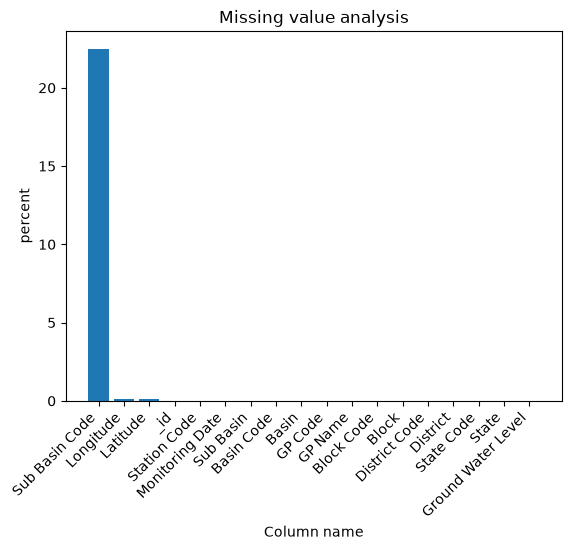

In [14]:
plt.Figure(figsize=(15,12))
plt.title("Missing value analysis")
plt.bar(missing_value_analysis.index,missing_value_analysis.values)
plt.xticks(rotation=45, ha='right')
plt.xlabel("Column name")
plt.ylabel("percent")
plt.show()

In [15]:
Latitude_null=df_clean["Latitude"].isnull()
longitude_null=df_clean["Longitude"].isnull()

In [16]:
missing_latitude_longitude=df_clean[Latitude_null | longitude_null][["Station Code","District","Block","GP Name","Latitude","Longitude"]]
print(missing_latitude_longitude.head(10))

      Station Code    District       Block GP Name  Latitude  Longitude
29805     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29806     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29807     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29808     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29809     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29810     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29811     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29812     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29813     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN
29814     050910HP  Vijayapura  Muddebihal       -   16.2527        NaN


How many unique stations have missing latitude?



How many unique stations have missing longitude?

In [17]:
df_clean[Latitude_null]["Station Code"].nunique()

7

In [18]:
df_clean[longitude_null]["Station Code"].nunique()

7

To see the unique station code for above


In [19]:
df_clean[Latitude_null]["Station Code"].unique()

<ArrowStringArray>
['100809', '100813', '100815', '100817', '100903', '100913', '100915']
Length: 7, dtype: str

In [20]:
df_clean[longitude_null]["Station Code"].unique()

<ArrowStringArray>
['050910HP', '100809', '100813', '100815', '100903', '100913', '100915']
Length: 7, dtype: str

We need to check whether these stations have coordinates available in any other observations.

In [21]:
df_clean[df_clean["Station Code"].astype(str)=="050910HP"]

,_id,Station Code,State,State Code,District,District Code,Block,Block Code,GP Name,GP Code,Basin,Basin Code,Sub Basin,Sub Basin Code,Latitude,Longitude,Monitoring Date,Ground Water Level
29805,29806,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-01-01,2.45
29806,29807,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-02-01,2.80
29807,29808,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-03-01,3.45
29808,29809,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-04-01,3.59
29809,29810,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-05-01,4.80
29810,29811,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-06-01,7.70
29811,29812,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-07-01,5.80
29812,29813,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-08-01,4.45
29813,29814,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-09-01,3.20
29814,29815,050910HP,Karnataka,10,Vijayapura,170,Muddebihal,39,-,-,Krishna,7,-,NaN,16.2527,NaN,2021-10-01,2.30


I want you to determine whether each affected station has:
- A consistent latitude.
- A consistent longitude.
- Any available coordinate values elsewhere in its records.

In [22]:
summary = df_clean.groupby("Station Code").agg(
    Latitude_null=("Latitude", lambda x: x.isnull().sum()),
    Longitude_null=("Longitude", lambda x: x.isnull().sum()),
    Latitude_unique=("Latitude", "nunique"),
    Longitude_unique=("Longitude", "nunique")
)

In [23]:
print(summary.head(10))

              Latitude_null  Longitude_null  Latitude_unique  Longitude_unique
Station Code                                                                  
010801D                   0               0                1                 1
020109b                   0               0                1                 1
020116a                   0               0                1                 1
020203A                   0               0                1                 1
020204C                   0               0                1                 1
020206A                   0               0                1                 1
020402a                   0               0                1                 1
020405a                   0               0                1                 1
020408A                   0               0                1                 1
020503A                   0               0                1                 1


In [24]:
summary[(summary["Latitude_null"].astype(int)>0) | (summary["Longitude_null"].astype(int)>0)]

,Latitude_null,Longitude_null,Latitude_unique,Longitude_unique
Station Code,,,,
050910HP,0,60,1,0
100809,12,12,0,0
100813,12,12,0,0
100815,16,16,0,0
100817,43,0,0,1
100903,12,12,0,0
100913,12,12,0,0
100915,12,12,0,0


investigate station 100817.

Find its available latitude values and determine whether it has exactly one unique non-null latitude.

In [25]:
df_clean[df_clean["Station Code"].astype(str)=="100817"]


,_id,Station Code,State,State Code,District,District Code,Block,Block Code,GP Name,GP Code,Basin,Basin Code,Sub Basin,Sub Basin Code,Latitude,Longitude,Monitoring Date,Ground Water Level
64028,64029,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2022-06-01,2.30
64029,64030,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2022-07-01,1.95
64030,64031,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2022-08-01,1.65
64031,64032,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2022-09-01,0.25
64032,64033,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2022-10-01,0.55
64033,64034,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2022-11-01,0.80
64034,64035,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2022-12-01,1.55
64035,64036,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2023-01-01,1.65
64036,64037,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2023-02-01,2.35
64037,64038,100817,Karnataka,10,Yadgir,597,Wadagera,3181,-,-,Krishna,7,-,NaN,NaN,77.098715,2023-03-01,2.50


investigate the missing Sub Basin Code values

In [26]:
sub_Basin_code_missing=df_clean["Sub Basin Code"].isnull()

In [27]:
df_clean[sub_Basin_code_missing][["Station Code","District","Block","Basin","Basin Code","Sub Basin","Sub Basin Code"]]

,Station Code,District,Block,Basin,Basin Code,Sub Basin,Sub Basin Code
18101,30103,Ballari,Ballari,Krishna,7,-,NaN
18102,30103,Ballari,Ballari,Krishna,7,-,NaN
18103,30103,Ballari,Ballari,Krishna,7,-,NaN
18104,30103,Ballari,Ballari,Krishna,7,-,NaN
18105,30103,Ballari,Ballari,Krishna,7,-,NaN
...,...,...,...,...,...,...,...
124355,CGWB1,Ballari,Ballari,Krishna,7,-,NaN
124356,CGWB1,Ballari,Ballari,Krishna,7,-,NaN
124357,CGWB1,Ballari,Ballari,Krishna,7,-,NaN
124358,CGWB1,Ballari,Ballari,Krishna,7,-,NaN


In [28]:
df_clean.loc[sub_Basin_code_missing, "Sub Basin"].value_counts()

Sub Basin
-    27971
Name: count, dtype: int64

Detecting dupicate 

In [31]:
duplicates = df_clean.duplicated(
    subset=["Station Code", "Monitoring Date"],
    keep=False
)
# Count duplicate rows
print("Number of duplicate rows:", duplicates.sum())

# Display duplicate records
df_clean[duplicates].sort_values(
    by=["Station Code", "Monitoring Date"]
)

Number of duplicate rows: 0


,_id,Station Code,State,State Code,District,District Code,Block,Block Code,GP Name,GP Code,Basin,Basin Code,Sub Basin,Sub Basin Code,Latitude,Longitude,Monitoring Date,Ground Water Level


Validate data types

In [32]:
df_clean.dtypes

_id                            int64
Station Code                     str
State                            str
State Code                     int64
District                         str
District Code                  int64
Block                            str
Block Code                     int64
GP Name                          str
GP Code                          str
Basin                            str
Basin Code                    object
Sub Basin                        str
Sub Basin Code               float64
Latitude                     float64
Longitude                    float64
Monitoring Date       datetime64[us]
Ground Water Level           float64
dtype: object

Investigate Basin Code

In [36]:
df_clean["Basin Code"].unique()

array([9, 8, 25, 7, 6, '7', '9', '-', '15', '8'], dtype=object)

In [39]:
df_clean["Basin Code"].value_counts(dropna=False)

Basin Code
7     41803
9     27524
7     20494
8      8135
15     7969
25     7222
-      4356
9      4336
6      2161
8       384
Name: count, dtype: int64

In [40]:
df_clean["Basin Code"].apply(type)

0         <class 'int'>
1         <class 'int'>
2         <class 'int'>
3         <class 'int'>
4         <class 'int'>
              ...      
124379    <class 'str'>
124380    <class 'str'>
124381    <class 'str'>
124382    <class 'str'>
124383    <class 'str'>
Name: Basin Code, Length: 124384, dtype: object

In [44]:
df_clean["Basin Code"].apply(type).value_counts()

Basin Code
<class 'int'>    65536
<class 'str'>    58848
Name: count, dtype: int64

Next task – Investigate other non-numeric values

In [51]:
df_clean.loc[
    df_clean["Basin Code"].apply(lambda x:isinstance(x,str)),
    "Basin Code"
].value_counts(dropna=False)

Basin Code
7     41803
15     7969
-      4356
9      4336
8       384
Name: count, dtype: int64

let's check whether "-" is also used in other categorical columns:
- Sub Basin
- GP Name
- GP Code

In [53]:
df_clean["GP Code"].unique()

<ArrowStringArray>
[   '-',  '155', '6915',  '188',  '216',  '220', '7231', '5302',  '227',
  '222',
 ...
 '4501',  '810',  '783',  '940',   '33', '1152', '1172', '2576', '7094',
 '1903']
Length: 1335, dtype: str

In [54]:
df_clean["GP Code"].value_counts()

GP Code
-       58730
5332      415
4515      180
4659      180
4764      180
        ...  
3416       20
3407       19
3171       17
2556       12
1358       12
Name: count, Length: 1335, dtype: int64

In [57]:
df_clean["GP Name"].value_counts(dropna=False)

GP Name
-                    58730
ULB-Shivamogga-CC      415
Hebri                  180
Sunkasala              180
Halageri               180
                     ...  
Kinnal                  20
Hatti                   19
Angarekanahalli         17
Khanapur                12
Kongarahalli            12
Name: count, Length: 1268, dtype: int64

In [77]:
df_clean["Sub Basin"].value_counts(dropna=False)

Sub Basin
-                   27971
Tungabhadra         19053
Vedavati            13035
Upper Cauvery       11746
Malaprabha          10607
Pennar               8135
Palar                7222
Arkavati             6275
Shimsha              3615
Bhima                3367
Middle Cauvery       2813
Ghataprabha          2536
Upper Krishna        1523
Gangavali            1434
Aghanashini          1380
Suvarnavati          1364
W F Rivers Basin      772
Swarna                696
Haladi                440
Sita                  328
K8                     72
Name: count, dtype: int64

In [63]:
df_clean["Sub Basin Code"].value_counts(dropna=False)

Sub Basin Code
NaN      27971
20.0     19053
229.0    13035
24.0     11746
226.0    10607
23.0      8135
237.0     7222
232.0     6275
231.0     3615
227.0     3367
233.0     2813
225.0     2536
223.0     1523
126.0     1434
114.0     1380
230.0     1364
113.0      772
154.0      696
128.0      440
153.0      328
242.0       72
Name: count, dtype: int64

Investigate rows where Sub Basin Code is missing but Sub Basin is not -

In [76]:
df_clean[(df_clean["Sub Basin Code"].isnull()) & (df_clean["Sub Basin"].astype(str)!="-")]

,_id,Station Code,State,State Code,District,District Code,Block,Block Code,GP Name,GP Code,Basin,Basin Code,Sub Basin,Sub Basin Code,Latitude,Longitude,Monitoring Date,Ground Water Level


Before changing data types, let's verify whether each Basin name always maps to the same Basin Code.

In [80]:
summary=df_clean.groupby(by="Basin").agg(
    Unique=("Basin Code","nunique")
)
print(summary)

                  Unique
Basin                   
-                      1
Cauvery                2
Godavari               1
Krishna                2
Palar                  1
Pennar                 2
W F Rivers Basin       1


Let's inspect the unique Basin Code values for each basin.

In [84]:
df_clean[df_clean["Basin"].astype(str)=="Krishna"]["Basin Code"].unique()

array([7, '7'], dtype=object)

In [85]:
df_clean[df_clean["Basin"].astype(str)=="Cauvery"]["Basin Code"].unique()

array([9, '9'], dtype=object)

In [86]:
df_clean[df_clean["Basin"].astype(str)=="Pennar"]["Basin Code"].unique()

array([8, '8'], dtype=object)

Standardize Basin Code
We need to handle three things:
1. Convert numeric basin codes into a consistent string format.
2. Convert "-" placeholders into missing values (NaN).
3. Preserve existing missing values without turning them into the string "nan".

In [87]:
df_clean["Basin Code"] = (
    df_clean["Basin Code"]
    .replace("-", pd.NA)
    .astype("string")
)

In [89]:
print(df_clean["Basin Code"].dtype)
print(df_clean["Basin Code"].unique())
print(df_clean["Basin Code"].isnull().sum())

string
<ArrowStringArray>
['9', '8', '25', '7', '6', <NA>, '15']
Length: 7, dtype: string
4356


In [90]:
summary=df_clean.groupby(by="Basin").agg(
    Unique=("Basin Code","nunique")
)
print(summary)

                  Unique
Basin                   
-                      0
Cauvery                1
Godavari               1
Krishna                1
Palar                  1
Pennar                 1
W F Rivers Basin       1


Clean GP Code

In [92]:
print(df_clean["GP Code"].dtypes)

str


In [104]:
df_clean["GP Code"] = (
    df_clean["GP Code"]
    .replace("-", pd.NA)
    .astype("string")
)

In [107]:
print(df_clean["GP Code"].value_counts(dropna=False))

GP Code
<NA>    58730
5332      415
4515      180
4659      180
4764      180
        ...  
3416       20
3407       19
3171       17
2556       12
1358       12
Name: count, Length: 1335, dtype: int64[pyarrow]


In [108]:
print(df_clean["GP Code"].dtype)
print(df_clean["GP Code"].isnull().sum())
print(df_clean["GP Code"].unique()[:20])

string
58730
<ArrowStringArray>
[  <NA>,  '155', '6915',  '188',  '216',  '220', '7231', '5302',  '227',
  '222',  '226', '4853',  '224',  '219', '5634',  '221',  '223',  '229',
 '5636', '5639']
Length: 20, dtype: string


Clean GP Name

In [113]:
df_clean["GP Name"]=(df_clean["GP Name"].replace(to_replace="-",value=pd.NA).astype("string"))

In [117]:
print(df_clean["GP Name"].value_counts(dropna=False))

GP Name
<NA>                 58730
ULB-Shivamogga-CC      415
Hebri                  180
Sunkasala              180
Halageri               180
                     ...  
Kinnal                  20
Hatti                   19
Angarekanahalli         17
Khanapur                12
Kongarahalli            12
Name: count, Length: 1268, dtype: int64[pyarrow]


In [122]:
print(df_clean["Sub Basin"].unique())

<ArrowStringArray>
[        'Arkavati',           'Pennar',    'Upper Cauvery',
            'Palar',    'Upper Krishna',       'Malaprabha',
      'Ghataprabha',                '-',      'Tungabhadra',
         'Vedavati',               'K8',           'Swarna',
             'Sita',           'Haladi', 'W F Rivers Basin',
            'Bhima',          'Shimsha',      'Suvarnavati',
   'Middle Cauvery',        'Gangavali',      'Aghanashini']
Length: 21, dtype: str


In [124]:
print(df_clean[df_clean["Sub Basin"]=="K8"].shape[0])

72


In [134]:
(df_clean[df_clean["Sub Basin"]=="K8"])["District"].unique()

<ArrowStringArray>
['Chikkamagaluru']
Length: 1, dtype: str

In [135]:
(df_clean[df_clean["Sub Basin"]=="K8"])["Block"].unique()

<ArrowStringArray>
['Sringeri', 'Kalasa']
Length: 2, dtype: str

In [136]:
(df_clean[df_clean["Sub Basin"]=="K8"])["Basin"].unique()

<ArrowStringArray>
['Krishna']
Length: 1, dtype: str

In [137]:
(df_clean[df_clean["Sub Basin"]=="K8"])["Basin Code"].unique()

<ArrowStringArray>
['7']
Length: 1, dtype: string

In [138]:
k8_data = df_clean[df_clean["Sub Basin"] == "K8"]

print("Unique stations:", k8_data["Station Code"].nunique())
print("Station codes:", k8_data["Station Code"].unique())

Unique stations: 3
Station codes: <ArrowStringArray>
['60610', '60801', '60802']
Length: 3, dtype: str


Clean Sub Basin

In [142]:
df_clean["Sub Basin"]=(df_clean["Sub Basin"]
                 .replace(to_replace="-",value=pd.NA)
                 .astype("string"))

In [ ]:
print(df_clean["Sub Basin"].isnull().sum())
print(df_clean["Sub Basin"].value_counts(dropna=False))

27971
Sub Basin
<NA>                27971
Tungabhadra         19053
Vedavati            13035
Upper Cauvery       11746
Malaprabha          10607
Pennar               8135
Palar                7222
Arkavati             6275
Shimsha              3615
Bhima                3367
Middle Cauvery       2813
Ghataprabha          2536
Upper Krishna        1523
Gangavali            1434
Aghanashini          1380
Suvarnavati          1364
W F Rivers Basin      772
Swarna                696
Haladi                440
Sita                  328
K8                     72
Name: count, dtype: int64[pyarrow]


Investigate geographic identifier columns
We have three more columns to examine:
- State Code
- District Code
- Block Code

In [147]:
df_clean["State Code"].value_counts(dropna=False)

State Code
10    124384
Name: count, dtype: int64

In [151]:
df_clean["District Code"].value_counts(dropna=False)
df_clean["District Code"].dtypes

dtype('int64')

In [153]:
print(df_clean["District Code"].dtype)
print(df_clean["District Code"].isnull().sum())
print(df_clean["District Code"].nunique())

int64
0
31


In [161]:
#to check wheather each district match with exactly one district code
summary_district=(df_clean.groupby(by="District")
                  .agg(
                      Distinct_value=("District Code","nunique")
                  ))

In [162]:
print(summary_district)

                  Distinct_value
District                        
Bagalkot                       1
Ballari                        1
Belagavi                       1
Bengaluru Rural                1
Bengaluru Urban                1
Bidar                          1
Chamrajnagar                   1
Chikkaballapura                1
Chikkamagaluru                 1
Chitradurga                    1
Dakshina Kannada               1
Davangere                      1
Dharwad                        1
Gadag                          1
Hassan                         1
Haveri                         1
Kalaburagi                     1
Kodagu                         1
Kolar                          1
Koppal                         1
Mandya                         1
Mysuru                         1
Raichur                        1
Ramanagara                     1
Shivamogga                     1
Tumakuru                       1
Udupi                          1
Uttara Kannada                 1
Vijayanaga

In [160]:
#to check wheather each district match with exactly one district code
reverse_summary_district=(df_clean.groupby(by="District Code")
                  .agg(
                      Distinct_value=("District","nunique")
                  ))
print(reverse_summary_district)

               Distinct_value
District Code                
164                         1
165                         1
166                         1
167                         1
168                         1
169                         1
170                         1
171                         1
172                         1
173                         1
174                         1
175                         1
176                         1
177                         1
178                         1
179                         1
180                         1
181                         1
182                         1
183                         1
184                         1
185                         1
186                         1
187                         1
188                         1
189                         1
190                         1
191                         1
192                         1
597                         1
598                         1


In [165]:
print(df_clean["Block Code"].dtypes)
print(df_clean["Block Code"].value_counts(dropna=False))
print(df_clean["Block Code"].nunique())
print(df_clean["Block Code"].isnull().sum())


int64
Block Code
52      2244
53      1948
114     1923
46      1910
42      1837
        ... 
3180      74
109       70
171       60
881       60
4191      48
Name: count, Length: 236, dtype: int64
236
0


In [167]:
print(df_clean["Block Code"].unique())


[  11   12 2181   13  176  113    7    8    9  114 4194  115   10  116
   14  289   15  287   16   17  288   18  290   19   20   22   21   23
 4189   24 1384   25   66   27 1386   26   28 1385   29   30  683   31
   34   32   33  684  682   35    1  383    2   36  487  488  482   37
  483  486    3    4  384   38  484    5  385   39  485    6   40 4190
   45   46 1884   47   48   49   50   51 4191   52   53   65   67   54
   55   56   69   57  154 4195  155  156 2582 4196 2583  157  158  169
 1783 1780  170 1781  171 1782   94   70 1083   75   95   96   97 1284
 1082   71   72   73   76 1084   74   98  982   78   99  100   79  983
   77   80   81  587   82  588  593   83   84   85  589   86  172 3181
  173 3182  174 3180   87   89   88   90   91   92   93  175  101  102
 4193 4192  103   58  104 2088   59   60   61   63  105  106  107   62
  108  117  118  119  120  121  122  123   41   42  124 2784  125   43
 2881  126 4197  127  128  129  130   44  143  881  109  883  111  110
  144 

In [170]:
district_summary=df_clean.groupby("District").agg(
    unique_block=("Block","nunique"),
    unique_block_code=("Block Code","nunique")
)

In [171]:
print(district_summary)

                  unique_block  unique_block_code
District                                         
Bagalkot                     9                  9
Ballari                      5                  5
Belagavi                    15                 15
Bengaluru Rural              4                  4
Bengaluru Urban              5                  5
Bidar                        8                  8
Chamrajnagar                 5                  5
Chikkaballapura              6                  6
Chikkamagaluru               9                  9
Chitradurga                  6                  6
Dakshina Kannada             9                  9
Davangere                    6                  6
Dharwad                      8                  8
Gadag                        7                  7
Hassan                       8                  8
Haveri                       8                  8
Kalaburagi                  11                 11
Kodagu                       5                  5


In [172]:
block_mapping = (
    df_clean.groupby(["District", "Block"])
    .agg(
        Unique_Block_Codes=("Block Code", "nunique")
    )
)

print(block_mapping)

                      Unique_Block_Codes
District Block                          
Bagalkot Badami                        1
         Bagalkot                      1
         Bilgi                         1
         Guledagudda                   1
         Hungund                       1
...                                  ...
Yadgir   Hunasagi                      1
         Shahpur                       1
         Shorapur                      1
         Wadagera                      1
         Yadgir                        1

[236 rows x 1 columns]


In [173]:
block_mapping[block_mapping["Unique_Block_Codes"] != 1]

,,Unique_Block_Codes
District,Block,


In [175]:
block_mapping = (
    df_clean.groupby(["District", "Block Code"])
    .agg(
        Unique_Block_Codes=("Block", "nunique")
    )
)

print(block_mapping)
block_mapping[block_mapping["Unique_Block_Codes"] != 1]

                     Unique_Block_Codes
District Block Code                    
Bagalkot 1                            1
         2                            1
         3                            1
         4                            1
         5                            1
...                                 ...
Yadgir   173                          1
         174                          1
         3180                         1
         3181                         1
         3182                         1

[236 rows x 1 columns]


,,Unique_Block_Codes
District,Block Code,


Next task: Validate Station Code

In [180]:
print(df_clean["Station Code"].dtypes)
print(df_clean["Station Code"].isnull().sum())
print(df_clean["Station Code"].unique())
print(df_clean["Station Code"].nunique())

str
0
<ArrowStringArray>
[  '10101',   '10104',   '10105',   '10107',   '10108',   '10201',   '10203',
   '10204',   '10206',   '10210',
 ...
 '80409Hd', '80411Hd', '80412HD', '80502HD', '80504Hd', '80506Hd', '80508Hd',
   'CGWB1',   'CGWB2',   'CGWB3']
Length: 2709, dtype: str
2709


In [182]:
station_district = (
    df_clean.groupby("Station Code")
    .agg(
        Unique_Districts=("District", "nunique")
    )
)

print(station_district)
station_district[station_district["Unique_Districts"] != 1]

              Unique_Districts
Station Code                  
010801D                      1
020109b                      1
020116a                      1
020203A                      1
020204C                      1
...                        ...
91816                        1
91817                        1
CGWB1                        1
CGWB2                        1
CGWB3                        1

[2709 rows x 1 columns]


,Unique_Districts
Station Code,


Next task: Station → Block mapping

In [187]:
station_block = (
    df_clean.groupby("Station Code")
    .apply(lambda x:x[["District","Block"]].drop_duplicates().shape[0])
)

print(station_block)
station_block.value_counts()

Station Code
010801D    1
020109b    1
020116a    1
020203A    1
020204C    1
          ..
91816      1
91817      1
CGWB1      1
CGWB2      1
CGWB3      1
Length: 2709, dtype: int64


1    2709
Name: count, dtype: int64

In [188]:
summary_latitude_longitude=(df_clean.groupby(by="Station Code")
                            .agg(
                                unique_Latitude=("Latitude","nunique"),
                                unique_Longitude=("Longitude","nunique")
                            ))

In [192]:
summary_latitude_longitude[
    (summary_latitude_longitude["unique_Latitude"] != 1) |
    (summary_latitude_longitude["unique_Longitude"] != 1)
]

,unique_Latitude,unique_Longitude
Station Code,,
050910HP,1,0
100809,0,0
100813,0,0
100815,0,0
100817,0,1
100903,0,0
100913,0,0
100915,0,0


In [194]:
print("min latitude",df_clean["Latitude"].min())
print("Max latitude",df_clean["Latitude"].max())
print("Min Longitude",df_clean["Longitude"].min())
print("Max Longitude",df_clean["Longitude"].max())

min latitude 4.3
Max latitude 18.29099
Min Longitude 13.04278
Max Longitude 78.568611


In [195]:
suspicious_coordinates = df_clean[
    (df_clean["Latitude"] < 11) |
    (df_clean["Longitude"] < 74)
]

suspicious_coordinates[
    ["Station Code", "District", "Block", "Latitude", "Longitude"]
].drop_duplicates()

,Station Code,District,Block,Latitude,Longitude
15820,20816,Belagavi,Ramdurg,16.0723,17.23270
68056,110401,Hassan,Belur,4.3000,13.04278
72972,120318BW,Kodagu,Ponnampete,12.1353,16.05420


In [196]:
suspicious_station_codes = ["20816", "110401", "120318BW"]

# Filter the three suspicious stations
suspicious_station_data = df_clean[
    df_clean["Station Code"].isin(suspicious_station_codes)
]

# Generate station-wise summary
coordinate_summary = (
    suspicious_station_data.groupby("Station Code")
    .agg(
        Total_Observations=("Monitoring Date", "count"),
        Unique_Latitude=("Latitude", "nunique"),
        Unique_Longitude=("Longitude", "nunique"),
        Latitude_Values=("Latitude", lambda x: sorted(x.dropna().unique())),
        Longitude_Values=("Longitude", lambda x: sorted(x.dropna().unique()))
    )
)

print(coordinate_summary)

# Display all observations for these stations
print(
    suspicious_station_data[
        ["Station Code", "District", "Block",
         "Monitoring Date", "Latitude", "Longitude"]
    ].sort_values(["Station Code", "Monitoring Date"])
)

              Total_Observations  Unique_Latitude  Unique_Longitude  \
Station Code                                                          
110401                        60                1                 1   
120318BW                      60                1                 1   
20816                         60                1                 1   

             Latitude_Values Longitude_Values  
Station Code                                   
110401                 [4.3]       [13.04278]  
120318BW           [12.1353]        [16.0542]  
20816              [16.0723]        [17.2327]  
      Station Code  District    Block Monitoring Date  Latitude  Longitude
68056       110401    Hassan    Belur      2021-01-01    4.3000   13.04278
68057       110401    Hassan    Belur      2021-02-01    4.3000   13.04278
68058       110401    Hassan    Belur      2021-03-01    4.3000   13.04278
68059       110401    Hassan    Belur      2021-04-01    4.3000   13.04278
68060       110401    Hassan 

In [197]:
invalid_coordinates = df_clean[
    (df_clean["Latitude"] < 11) |
    (df_clean["Latitude"] > 19) |
    (df_clean["Longitude"] < 73) |
    (df_clean["Longitude"] > 79)
]

# Get unique affected stations
invalid_station_summary = (
    invalid_coordinates.groupby("Station Code")
    .agg(
        District=("District", "first"),
        Block=("Block", "first"),
        Total_Observations=("Monitoring Date", "count"),
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first")
    )
)

print("Number of affected stations:", len(invalid_station_summary))
print(invalid_station_summary)

Number of affected stations: 3
              District       Block  Total_Observations  Latitude  Longitude
Station Code                                                               
110401          Hassan       Belur                  60    4.3000   13.04278
120318BW        Kodagu  Ponnampete                  60   12.1353   16.05420
20816         Belagavi     Ramdurg                  60   16.0723   17.23270


Ground water level with negative reading 

In [198]:
Negative_reading_rows=df_clean[df_clean["Ground Water Level"]<0]

In [215]:
print(Negative_reading_rows.shape[0])
print(df_clean[df["Ground Water Level"]<0]["Station Code"].nunique())
print(df_clean[df_clean["Ground Water Level"]<0]["Ground Water Level"].value_counts(dropna=False))
summary_negative_reading_district_wise=(Negative_reading_rows.groupby(by="District")
                                        .agg(District_wise_distribution_of_negative=("Ground Water Level","count")))
print(summary_negative_reading_district_wise)

2726
316
Ground Water Level
-0.05    2720
-0.13       1
-0.30       1
-0.15       1
-0.17       1
-0.27       1
-0.50       1
Name: count, dtype: int64
                  District_wise_distribution_of_negative
District                                                
Bagalkot                                              63
Ballari                                               10
Belagavi                                             113
Bengaluru Urban                                       31
Bidar                                                  6
Chamrajnagar                                          14
Chikkaballapura                                       27
Chikkamagaluru                                       251
Chitradurga                                          118
Dakshina Kannada                                      14
Davangere                                             40
Dharwad                                               11
Gadag                                             

In [216]:
# Filter observations with -0.05 groundwater level
negative_005 = df_clean[
    df_clean["Ground Water Level"] == -0.05
]

# Station-wise summary
negative_station_summary = (
    negative_005.groupby("Station Code")
    .agg(
        District=("District", "first"),
        Block=("Block", "first"),
        Negative_Observations=("Ground Water Level", "count"),
        First_Monitoring_Date=("Monitoring Date", "min"),
        Last_Monitoring_Date=("Monitoring Date", "max"),
        Unique_Negative_Values=("Ground Water Level", "nunique")
    )
    .sort_values(
        by="Negative_Observations",
        ascending=False
    )
)

print("Total stations:", len(negative_station_summary))
print(negative_station_summary)

Total stations: 310
                    District         Block  Negative_Observations  \
Station Code                                                        
60802         Chikkamagaluru        Kalasa                     24   
60610         Chikkamagaluru      Sringeri                     24   
091716HP               Gadag  Lakshmeshwar                     24   
60309         Chikkamagaluru         Koppa                     24   
50606               Bagalkot         Ilkal                     19   
...                      ...           ...                    ...   
30125                Ballari      Kurugodu                      1   
20838               Belagavi       Ramdurg                      1   
70832              Davangere       Jagalur                      1   
50437             Vijayapura        Tikota                      1   
CGWB3           Vijayanagara  Harpanahalli                      1   

             First_Monitoring_Date Last_Monitoring_Date  \
Station Code           

Investigate the monthly pattern

In [217]:
# Filter -0.05 groundwater readings
negative_005 = df_clean[
    df_clean["Ground Water Level"] == -0.05
]

# Month-wise summary
monthly_negative_summary = (
    negative_005.groupby("Monitoring Date")
    .agg(
        Negative_Observations=("Ground Water Level", "count"),
        Affected_Stations=("Station Code", "nunique")
    )
    .sort_index()
)

print(monthly_negative_summary)

                 Negative_Observations  Affected_Stations
Monitoring Date                                          
2021-01-01                           1                  1
2021-02-01                           1                  1
2021-03-01                           1                  1
2021-04-01                           1                  1
2021-05-01                           1                  1
2021-06-01                           1                  1
2021-07-01                           1                  1
2021-08-01                           1                  1
2021-09-01                           1                  1
2021-10-01                           1                  1
2022-01-01                           4                  4
2022-02-01                           5                  5
2022-03-01                           5                  5
2022-04-01                           4                  4
2022-05-01                           1                  1
2022-06-01    

In [218]:
# 1. Total groundwater observations per month
monthly_total = (
    df_clean.groupby("Monitoring Date")
    .agg(
        Total_Observations=("Ground Water Level", "count"),
        Total_Stations=("Station Code", "nunique")
    )
)

# 2. Monthly -0.05 observations
negative_005 = df_clean[
    df_clean["Ground Water Level"] == -0.05
]

monthly_negative = (
    negative_005.groupby("Monitoring Date")
    .agg(
        Negative_Observations=("Ground Water Level", "count"),
        Affected_Stations=("Station Code", "nunique")
    )
)

# 3. Combine both summaries
monthly_comparison = monthly_total.join(
    monthly_negative,
    how="left"
)

# 4. Replace missing negative counts with zero
monthly_comparison[
    ["Negative_Observations", "Affected_Stations"]
] = monthly_comparison[
    ["Negative_Observations", "Affected_Stations"]
].fillna(0).astype(int)

# 5. Calculate percentage of negative observations
monthly_comparison["Negative_Percentage"] = (
    monthly_comparison["Negative_Observations"]
    / monthly_comparison["Total_Observations"]
) * 100

print(monthly_comparison)

                 Total_Observations  Total_Stations  Negative_Observations  \
Monitoring Date                                                              
2021-01-01                     1401            1401                      1   
2021-02-01                     1403            1403                      1   
2021-03-01                     1409            1409                      1   
2021-04-01                     1412            1412                      1   
2021-05-01                     1429            1429                      1   
2021-06-01                     1436            1436                      1   
2021-07-01                     1468            1468                      1   
2021-08-01                     1443            1443                      1   
2021-09-01                     1450            1450                      1   
2021-10-01                     1479            1479                      1   
2021-11-01                     1466            1466             

In [221]:
check_dates = pd.to_datetime([
    "2023-12-01",
    "2024-01-01",
    "2025-05-01",
    "2025-06-01",
    "2025-07-01"
])
befores=df_clean[df_clean["Monitoring Date"].isin(check_dates)]
comparison = (
    df_clean[df_clean["Monitoring Date"].isin(check_dates)]
    .pivot(
        index="Station Code",
        columns="Monitoring Date",
        values="Ground Water Level"
    )
)

comparison.columns = comparison.columns.strftime("%Y-%m")

In [223]:
print(comparison)

Monitoring Date  2023-12  2024-01  2025-05  2025-06  2025-07
Station Code                                                
010801D             4.10     5.40    17.07    16.03    16.10
020109b            28.12    45.21    13.12    13.19     8.15
020116a            38.27    35.67    38.64    35.66    31.34
020203A             3.10     4.84     3.68     2.28     2.11
020204C              NaN    14.77    12.62     8.64     7.07
...                  ...      ...      ...      ...      ...
91816                NaN     8.25     7.65     7.95     7.85
91817                NaN    -0.05     3.75     3.15     3.50
CGWB1                NaN     0.90      NaN      NaN      NaN
CGWB2                NaN    20.70      NaN      NaN      NaN
CGWB3                NaN    -0.05      NaN      NaN      NaN

[2709 rows x 5 columns]


In [226]:
negative_flags = comparison.eq(-0.05)
negative_flags.sum()

Monitoring Date
2023-12      0
2024-01    191
2025-05     55
2025-06      7
2025-07     49
dtype: int64

In [229]:
three_months = comparison[
    ["2025-05", "2025-06", "2025-07"]
].dropna()

flags = three_months.eq(-0.05)

print("Stations observed in all three months:", len(flags))

print("\nNegative readings in these stations:")
print(flags.sum())

print("\nMay to June transition:")
print(pd.crosstab(flags["2025-05"], flags["2025-06"]))

print("\nJune to July transition:")
print(pd.crosstab(flags["2025-06"], flags["2025-07"]))

Stations observed in all three months: 2572

Negative readings in these stations:
Monitoring Date
2025-05    55
2025-06     7
2025-07    49
dtype: int64

May to June transition:
2025-06  False  True 
2025-05              
False     2517      0
True        48      7

June to July transition:
2025-07  False  True 
2025-06              
False     2522     43
True         1      6


Next task: Identify the 48 stations

In [235]:
may_negative = set(
    flags.index[flags["2025-05"]]
)
june_negative = set(
    flags.index[flags["2025-06"]]
)

july_negative = set(
    flags.index[flags["2025-07"]]
)

may_to_june_changed = may_negative - june_negative

print("May negative, June not negative:",
      len(may_to_june_changed))

print("\nStations:")
print(sorted(may_to_june_changed))

May negative, June not negative: 48

Stations:
['120101', '120102', '120104', '120105DW', '120106', '120107', '120108', '120109', '120111BW', '120112HP', '120114DW', '120115Hp', '120116HP', '120117HP', '120118', '120119', '120120', '120121', '120204', '120205', '120208', '120210Hp', '120211HP', '120212BW', '120213', '120214', '120215', '120216', '120303', '120304', '120305', '120306', '120310', '120312DW', '120314HP', '120316BW', '120318BW', '120320Bw', '120321BW', '120323HP', '120325', '120326', '120327', '170906', '190302', '190307', '190704', '191111']


In [236]:
may_june_july_changes = comparison.loc[
    sorted(may_to_june_changed),
    ["2025-05", "2025-06", "2025-07"]
]

print(may_june_july_changes)

Monitoring Date  2025-05  2025-06  2025-07
Station Code                              
120101             -0.05     6.11    -0.05
120102             -0.05     0.91    -0.05
120104             -0.05     7.82    -0.05
120105DW           -0.05     9.37    -0.05
120106             -0.05     3.29    -0.05
120107             -0.05    19.83    -0.05
120108             -0.05    11.51    -0.05
120109             -0.05    11.78    -0.05
120111BW           -0.05    14.06    -0.05
120112HP           -0.05    13.62    -0.05
120114DW           -0.05     6.83    -0.05
120115Hp           -0.05    28.03    -0.05
120116HP           -0.05    12.04    -0.05
120117HP           -0.05    17.95    -0.05
120118             -0.05    11.89    -0.05
120119             -0.05     8.27    -0.05
120120             -0.05    23.12    -0.05
120121             -0.05    23.29    -0.05
120204             -0.05     4.28    -0.05
120205             -0.05     5.25    -0.05
120208             -0.05     0.84    -0.05
120210Hp   

In [237]:
may_june_july_changes.describe()

Monitoring Date,2025-05,2025-06,2025-07
count,4.800000e+01,48.000000,48.000000
mean,-5.000000e-02,12.465000,0.264792
std,7.012323e-18,9.565799,1.179044
min,-5.000000e-02,0.840000,-0.050000
25%,-5.000000e-02,6.107500,-0.050000
50%,-5.000000e-02,10.215000,-0.050000
75%,-5.000000e-02,18.180000,-0.050000
max,-5.000000e-02,55.490000,6.700000


In [238]:
may_june_july_changes["2025-06"].value_counts().sort_index()

2025-06
0.84     1
0.90     1
0.91     1
1.85     1
2.45     1
3.22     1
3.29     1
4.20     1
4.28     1
4.99     1
5.25     1
6.10     1
6.11     1
6.83     1
7.82     1
7.90     1
8.27     1
8.82     1
9.12     1
9.20     1
9.37     1
9.57     1
9.60     1
9.87     1
10.56    1
11.51    1
11.78    1
11.89    1
12.04    1
12.15    1
13.48    1
13.62    1
13.79    1
14.06    1
14.85    1
17.95    1
18.87    1
19.23    1
19.83    1
19.93    1
20.43    1
22.00    1
23.12    1
23.29    1
23.68    1
25.98    1
28.03    1
55.49    1
Name: count, dtype: int64

In [239]:
may_june_july_changes[
    may_june_july_changes["2025-07"] == -0.05
]

Monitoring Date,2025-05,2025-06,2025-07
Station Code,,,
120101,-0.05,6.11,-0.05
120102,-0.05,0.91,-0.05
120104,-0.05,7.82,-0.05
120105DW,-0.05,9.37,-0.05
120106,-0.05,3.29,-0.05
120107,-0.05,19.83,-0.05
120108,-0.05,11.51,-0.05
120109,-0.05,11.78,-0.05
120111BW,-0.05,14.06,-0.05


In [240]:
station_details = (
    df_clean[
        df_clean["Station Code"].isin(may_to_june_changed)
    ]
    .groupby("Station Code")
    .agg(
        District=("District", "first"),
        Block=("Block", "first"),
        GP_Name=("GP Name", "first"),
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first")
    )
)

print(station_details)

                    District            Block             GP_Name  Latitude  \
Station Code                                                                  
120101                Kodagu         Madikeri                <NA>  12.42470   
120102                Kodagu         Madikeri             Sampaje  12.45170   
120104                Kodagu         Madikeri                <NA>  12.38220   
120105DW              Kodagu         Madikeri                <NA>  12.36580   
120106                Kodagu         Madikeri        Bhagamandala  12.38530   
120107                Kodagu         Madikeri             Napoklu  12.31140   
120108                Kodagu         Madikeri            Kunijala  12.26260   
120109                Kodagu         Madikeri                <NA>  12.22810   
120111BW              Kodagu         Madikeri             Sampaje  12.49560   
120112HP              Kodagu         Madikeri            Kunijala  12.26280   
120114DW              Kodagu         Madikeri       

In [241]:
print("District distribution:")
print(station_details["District"].value_counts())

print("\nBlock distribution:")
print(
    station_details.groupby(
        ["District", "Block"]
    ).size().sort_values(ascending=False)
)

District distribution:
District
Kodagu            43
Uttara Kannada     4
Shivamogga         1
Name: count, dtype: int64

Block distribution:
District        Block          
Kodagu          Madikeri           18
                Ponnampete         10
                Somvarpet           8
                Virarajendrapet     5
                Kushalanagara       2
Uttara Kannada  Haliyal             2
Shivamogga      Tirthahalli         1
Uttara Kannada  Mundgod             1
                Yellapur            1
dtype: int64


Next task: Investigate extreme groundwater values above 100 metres
Now let's investigate the other important data-quality concern.

We previously found:
- 1,750 observations above 100 metres.
- 137 stations affected.
- Several stations have consistently deep groundwater readings.
We must distinguish between:
1. Genuine deep groundwater levels.
2. Sudden unusual readings.
3. Potential measurement or data-entry errors.

In [242]:
extreme_readings = df_clean[
    df_clean["Ground Water Level"] > 100
]

print("Total observations above 100:",
      len(extreme_readings))

print("Unique stations:",
      extreme_readings["Station Code"].nunique())

print("\nDistrict distribution:")
print(extreme_readings["District"].value_counts())

Total observations above 100: 1750
Unique stations: 137

District distribution:
District
Bengaluru Rural    637
Kolar              548
Chikkaballapura    347
Ramanagara          48
Bagalkot            44
Belagavi            43
Tumakuru            32
Bengaluru Urban     24
Vijayapura          14
Davangere            8
Chamrajnagar         3
Hassan               2
Name: count, dtype: int64


In [243]:
extreme_station_summary = (
    extreme_readings.groupby("Station Code")
    .agg(
        District=("District", "first"),
        Block=("Block", "first"),
        Extreme_Observations=("Ground Water Level", "count"),
        First_Date=("Monitoring Date", "min"),
        Last_Date=("Monitoring Date", "max"),
        Minimum_Level=("Ground Water Level", "min"),
        Maximum_Level=("Ground Water Level", "max"),
        Average_Level=("Ground Water Level", "mean")
    )
    .sort_values(
        by="Extreme_Observations",
        ascending=False
    )
)

print(extreme_station_summary.head(20))

                     District          Block  Extreme_Observations First_Date  \
Station Code                                                                    
131120                  Kolar    Srinivaspur                    60 2021-01-01   
130812                  Kolar          Malur                    60 2021-01-01   
130815                  Kolar          Malur                    59 2021-01-01   
130805                  Kolar          Malur                    41 2021-01-01   
131121                  Kolar    Srinivaspur                    40 2021-03-01   
10523         Bengaluru Rural    Devanahalli                    40 2022-02-01   
10522         Bengaluru Rural    Devanahalli                    39 2022-02-01   
10525         Bengaluru Rural    Devanahalli                    39 2022-02-01   
10529         Bengaluru Rural    Devanahalli                    39 2022-03-01   
10516         Bengaluru Rural    Devanahalli                    38 2022-03-01   
10729         Bengaluru Rura

Next task: Investigate whether extreme readings are sudden or persistent

In [244]:
station_130815 = (
    df_clean[
        df_clean["Station Code"] == "130815"
    ]
    .sort_values("Monitoring Date")
    [["Monitoring Date", "Ground Water Level"]]
    .copy()
)

station_130815["Previous_Level"] = (
    station_130815["Ground Water Level"].shift(1)
)

station_130815["Monthly_Change"] = (
    station_130815["Ground Water Level"]
    - station_130815["Previous_Level"]
)

print(station_130815)

      Monitoring Date  Ground Water Level  Previous_Level  Monthly_Change
81941      2021-01-01              106.90             NaN             NaN
81942      2021-02-01              105.40          106.90           -1.50
81943      2021-03-01              105.93          105.40            0.53
81944      2021-04-01              104.45          105.93           -1.48
81945      2021-05-01              106.40          104.45            1.95
81946      2021-06-01              108.75          106.40            2.35
81947      2021-07-01              117.65          108.75            8.90
81948      2021-08-01              138.90          117.65           21.25
81949      2021-09-01              203.30          138.90           64.40
81950      2021-10-01              201.81          203.30           -1.49
81951      2021-11-01              145.25          201.81          -56.56
81952      2021-12-01              206.44          145.25           61.19
81953      2022-01-01              138

In [245]:
station_130815["Absolute_Change"] = (
    station_130815["Monthly_Change"].abs()
)

print(
    station_130815.nlargest(
        10, "Absolute_Change"
    )
)

      Monitoring Date  Ground Water Level  Previous_Level  Monthly_Change  \
81976      2023-12-01              221.84           21.64          200.20   
81975      2023-11-01               21.64          216.01         -194.37   
81953      2022-01-01              138.90          206.44          -67.54   
81949      2021-09-01              203.30          138.90           64.40   
81952      2021-12-01              206.44          145.25           61.19   
81966      2023-02-01              216.05          156.19           59.86   
81951      2021-11-01              145.25          201.81          -56.56   
81948      2021-08-01              138.90          117.65           21.25   
81955      2022-03-01              149.25          131.03           18.22   
81983      2024-07-01              210.37          225.94          -15.57   

       Absolute_Change  
81976           200.20  
81975           194.37  
81953            67.54  
81949            64.40  
81952            61.19  
81

In [246]:
malur_comparison = (
    df_clean[
        (df_clean["District"] == "Kolar") &
        (df_clean["Block"] == "Malur") &
        (df_clean["Monitoring Date"].isin(
            pd.to_datetime([
                "2023-10-01",
                "2023-11-01",
                "2023-12-01"
            ])
        ))
    ]
    .pivot(
        index="Station Code",
        columns="Monitoring Date",
        values="Ground Water Level"
    )
)

malur_comparison.columns = (
    malur_comparison.columns.strftime("%Y-%m")
)

print(malur_comparison)

Monitoring Date  2023-10  2023-11  2023-12
Station Code                              
130801             14.15    12.43    13.36
130802              9.42     7.66     9.55
130803             13.45    13.24    14.35
130804              4.19     5.38     6.45
130805             75.17    75.24    73.45
130806             18.90    17.03    18.71
130807              9.72     8.65    12.20
130808              3.87     3.07     4.15
130809             11.59    10.25    13.30
130810              2.11     1.60     2.47
130811             15.56    14.95    17.18
130812            160.44   160.43   160.43
130813             92.31    86.23    90.12
130814             16.88    14.66    16.80
130815            216.01    21.64   221.84


In [247]:
malur_comparison["Oct_to_Nov"] = (
    malur_comparison["2023-11"]
    - malur_comparison["2023-10"]
)

malur_comparison["Nov_to_Dec"] = (
    malur_comparison["2023-12"]
    - malur_comparison["2023-11"]
)

print(
    malur_comparison.sort_values(
        "Oct_to_Nov",
        key=lambda x: x.abs(),
        ascending=False
    )
)


Monitoring Date  2023-10  2023-11  2023-12  Oct_to_Nov  Nov_to_Dec
Station Code                                                      
130815            216.01    21.64   221.84     -194.37      200.20
130813             92.31    86.23    90.12       -6.08        3.89
130814             16.88    14.66    16.80       -2.22        2.14
130806             18.90    17.03    18.71       -1.87        1.68
130802              9.42     7.66     9.55       -1.76        1.89
130801             14.15    12.43    13.36       -1.72        0.93
130809             11.59    10.25    13.30       -1.34        3.05
130804              4.19     5.38     6.45        1.19        1.07
130807              9.72     8.65    12.20       -1.07        3.55
130808              3.87     3.07     4.15       -0.80        1.08
130811             15.56    14.95    17.18       -0.61        2.23
130810              2.11     1.60     2.47       -0.51        0.87
130803             13.45    13.24    14.35       -0.21        

2. Now let's investigate sudden changes across the entire dataset

In [249]:
df_sorted = df_clean.sort_values(
    ["Station Code", "Monitoring Date"]
).copy()

df_sorted["Previous_Level"] = (
    df_sorted.groupby("Station Code")[
        "Ground Water Level"
    ].shift(1)
)

df_sorted["Previous_Date"] = (
    df_sorted.groupby("Station Code")[
        "Monitoring Date"
    ].shift(1)
)

df_sorted["Month_Gap"] = (
    (df_sorted["Monitoring Date"].dt.year -
     df_sorted["Previous_Date"].dt.year) * 12
    +
    (df_sorted["Monitoring Date"].dt.month -
     df_sorted["Previous_Date"].dt.month)
)

df_sorted["Monthly_Change"] = (
    df_sorted["Ground Water Level"]
    - df_sorted["Previous_Level"]
)

df_sorted["Absolute_Change"] = (
    df_sorted["Monthly_Change"].abs()
)

In [250]:
consecutive_changes = df_sorted[
    df_sorted["Month_Gap"] == 1
].copy()

In [251]:
consecutive_changes["Absolute_Change"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.995]
)

count    121340.000000
mean          2.135573
std           5.067968
min           0.000000
90%           4.690000
95%           7.800000
99%          21.092200
99.5%        30.936100
max         200.200000
Name: Absolute_Change, dtype: float64

In [252]:
threshold_counts = {
    threshold: (
        consecutive_changes["Absolute_Change"] > threshold
    ).sum()
    for threshold in [10, 25, 50, 100, 150]
}

print(threshold_counts)

{10: np.int64(4189), 25: np.int64(891), 50: np.int64(221), 100: np.int64(31), 150: np.int64(12)}


3. Next task: Inspect the 31 largest changes

In [253]:
extreme_changes = (
    consecutive_changes[
        consecutive_changes["Absolute_Change"] > 100
    ]
    .sort_values(
        "Absolute_Change",
        ascending=False
    )
)

print(
    extreme_changes[
        [
            "Station Code",
            "District",
            "Block",
            "Previous_Date",
            "Monitoring Date",
            "Previous_Level",
            "Ground Water Level",
            "Monthly_Change",
            "Absolute_Change"
        ]
    ].to_string(index=False)
)

Station Code        District          Block Previous_Date Monitoring Date  Previous_Level  Ground Water Level  Monthly_Change  Absolute_Change
      130815           Kolar          Malur    2023-11-01      2023-12-01           21.64             221.840         200.200          200.200
      130815           Kolar          Malur    2023-10-01      2023-11-01          216.01              21.640        -194.370          194.370
      130234           Kolar     Bangarapet    2024-06-01      2024-07-01           -0.05             192.350         192.400          192.400
      130925           Kolar       Mulbagal    2025-10-01      2025-11-01          189.70               2.400        -187.300          187.300
      130901           Kolar       Mulbagal    2025-10-01      2025-11-01            4.92             189.270         184.350          184.350
       50437      Vijayapura         Tikota    2024-02-01      2024-03-01           -0.05             155.300         155.350          155.350

Inspect the complete time series of recurring stations

In [254]:
stations_to_check = [
    "10734",
    "10736",
    "10744",
    "10516",
    "20229",
    "20231",
    "130815"
]

repeated_station_analysis = (
    df_sorted[
        df_sorted["Station Code"].isin(stations_to_check)
    ][
        [
            "Station Code",
            "District",
            "Block",
            "Monitoring Date",
            "Ground Water Level"
        ]
    ]
    .sort_values(
        ["Station Code", "Monitoring Date"]
    )
)

print(repeated_station_analysis.to_string(index=False))

Station Code        District       Block Monitoring Date  Ground Water Level
       10516 Bengaluru Rural Devanahalli      2022-03-01              244.00
       10516 Bengaluru Rural Devanahalli      2022-05-01              190.00
       10516 Bengaluru Rural Devanahalli      2022-10-01              190.87
       10516 Bengaluru Rural Devanahalli      2022-11-01              185.62
       10516 Bengaluru Rural Devanahalli      2022-12-01              182.34
       10516 Bengaluru Rural Devanahalli      2023-01-01               44.54
       10516 Bengaluru Rural Devanahalli      2023-03-01               50.50
       10516 Bengaluru Rural Devanahalli      2023-04-01              151.16
       10516 Bengaluru Rural Devanahalli      2023-05-01              146.19
       10516 Bengaluru Rural Devanahalli      2023-06-01              155.44
       10516 Bengaluru Rural Devanahalli      2023-07-01              143.99
       10516 Bengaluru Rural Devanahalli      2023-08-01              141.99

Next task: Investigate whether 10736 and 10744 are duplicate stations

In [255]:
duplicate_station_check = (
    df_clean[
        df_clean["Station Code"].isin(["10736", "10744"])
    ]
    .sort_values(["Station Code", "Monitoring Date"])
)

metadata_columns = [
    "Station Code",
    "District",
    "Block",
    "GP Name",
    "GP Code",
    "Basin",
    "Basin Code",
    "Latitude",
    "Longitude"
]

for col in metadata_columns:
    print(f"\n{col}")
    print(
        duplicate_station_check
        .groupby("Station Code")[col]
        .unique()
    )


Station Code
Station Code
10736    [10736]
10744    [10744]
Name: Station Code, dtype: object

District
Station Code
10736    [Bengaluru Rural]
10744    [Bengaluru Rural]
Name: District, dtype: object

Block
Station Code
10736    [Hoskote]
10744    [Hoskote]
Name: Block, dtype: object

GP Name
Station Code
10736    [Kambalipura]
10744       [Sulibele]
Name: GP Name, dtype: object

GP Code
Station Code
10736     [267]
10744    [7047]
Name: GP Code, dtype: object

Basin
Station Code
10736    [Pennar]
10744    [Pennar]
Name: Basin, dtype: object

Basin Code
Station Code
10736    [8]
10744    [8]
Name: Basin Code, dtype: object

Latitude
Station Code
10736    [13.131]
10744    [13.186]
Name: Latitude, dtype: object

Longitude
Station Code
10736    [77.804]
10744    [77.808]
Name: Longitude, dtype: object


In [256]:
station_comparison = (
    duplicate_station_check
    .pivot(
        index="Monitoring Date",
        columns="Station Code",
        values="Ground Water Level"
    )
)

print(station_comparison.to_string())

print(
    "\nIdentical readings:",
    station_comparison["10736"].eq(
        station_comparison["10744"]
    ).sum()
)

print(
    "\nTotal common observations:",
    station_comparison.dropna().shape[0]
)

Station Code      10736   10744
Monitoring Date                
2022-02-01       193.50  193.50
2022-03-01       205.00  205.00
2022-04-01       193.00  193.00
2022-05-01        41.00   41.00
2022-06-01       193.00  193.00
2022-07-01       189.20  189.20
2022-08-01       185.70  185.70
2022-09-01       172.76  172.76
2022-10-01       111.01  111.01
2022-11-01        91.90   91.90
2022-12-01        82.56   82.56
2023-01-01        74.84   74.84
2023-02-01        78.54   78.54
2023-03-01        58.05   58.05
2023-04-01       101.40  101.40
2023-05-01        96.12   96.12
2023-06-01        96.89   96.89
2023-07-01        80.40   80.40
2023-08-01        94.50   94.50
2023-09-01        79.69   79.69
2023-10-01        86.92   86.92
2023-11-01        87.23   87.23
2023-12-01        91.93   91.93
2024-01-01       110.55  110.55
2024-02-01       128.95  128.95
2024-03-01       157.80  157.80
2024-04-01       175.29  175.29
2024-05-01       183.50  183.50
2024-06-01       179.91  179.91
2024-07-

In [257]:
# 1. Negative groundwater readings
df_clean["negative_level_flag"] = (
    df_clean["Ground Water Level"] < 0
)


# 2. Large consecutive monthly changes
large_change_indices = consecutive_changes.loc[
    consecutive_changes["Absolute_Change"] > 100
].index

df_clean["large_monthly_change_flag"] = (
    df_clean.index.isin(large_change_indices)
)


# 3. Identify identical readings between stations 10736 and 10744

shared_dates = station_comparison.index[
    station_comparison["10736"].eq(
        station_comparison["10744"]
    )
]

df_clean["shared_reading_review_flag"] = (
    df_clean["Station Code"].isin(["10736", "10744"])
    &
    df_clean["Monitoring Date"].isin(shared_dates)
)

In [258]:
flag_columns = [
    "negative_level_flag",
    "large_monthly_change_flag",
    "shared_reading_review_flag"
]

for col in flag_columns:
    print(f"\n{col}")
    print(df_clean[col].value_counts())


negative_level_flag
negative_level_flag
False    121658
True       2726
Name: count, dtype: int64

large_monthly_change_flag
large_monthly_change_flag
False    124353
True         31
Name: count, dtype: int64

shared_reading_review_flag
shared_reading_review_flag
False    124314
True         70
Name: count, dtype: int64


Create coordinate-quality flags

In [259]:
coordinate_summary = (
    df_clean.groupby("Station Code")
    .agg(
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first")
    )
    .reset_index()
)

In [261]:
coordinate_summary["missing_coordinate_flag"] = (
    coordinate_summary["Latitude"].isna()
    |
    coordinate_summary["Longitude"].isna()
)

In [262]:
coordinate_summary["suspicious_coordinate_flag"] = (
    (coordinate_summary["Latitude"] < 11)
    |
    (coordinate_summary["Latitude"] > 19)
    |
    (coordinate_summary["Longitude"] < 73)
    |
    (coordinate_summary["Longitude"] > 79)
)

In [263]:
coordinate_summary[
    coordinate_summary["missing_coordinate_flag"]
    |
    coordinate_summary["suspicious_coordinate_flag"]
]

,Station Code,Latitude,Longitude,missing_coordinate_flag,suspicious_coordinate_flag
84,050910HP,16.2527,NaN,True,False
246,100809,NaN,NaN,True,False
249,100813,NaN,NaN,True,False
250,100815,NaN,NaN,True,False
252,100817,NaN,77.098715,True,False
255,100903,NaN,NaN,True,False
264,100913,NaN,NaN,True,False
265,100915,NaN,NaN,True,False
535,110401,4.3000,13.042780,False,True
660,120318BW,12.1353,16.054200,False,True


In [264]:
coordinate_flags = coordinate_summary[
    [
        "Station Code",
        "missing_coordinate_flag",
        "suspicious_coordinate_flag"
    ]
]

df_clean = df_clean.merge(
    coordinate_flags,
    on="Station Code",
    how="left",
    validate="many_to_one"
)

In [265]:
print(
    df_clean[
        [
            "missing_coordinate_flag",
            "suspicious_coordinate_flag"
        ]
    ].sum()
)

missing_coordinate_flag       179
suspicious_coordinate_flag    180
dtype: int64


Inspect missing-coordinate stations

In [266]:
missing_stations = coordinate_summary[
    coordinate_summary["missing_coordinate_flag"]
]["Station Code"]

missing_station_counts = (
    df_clean[
        df_clean["Station Code"].isin(missing_stations)
    ]
    .groupby("Station Code")
    .agg(
        Total_Observations=("Monitoring Date", "count"),
        Latitude_Missing=("Latitude", lambda x: x.isna().sum()),
        Longitude_Missing=("Longitude", lambda x: x.isna().sum())
    )
)

print(missing_station_counts)
print("\nTotal observations:")
print(missing_station_counts["Total_Observations"].sum())

              Total_Observations  Latitude_Missing  Longitude_Missing
Station Code                                                         
050910HP                      60                 0                 60
100809                        12                12                 12
100813                        12                12                 12
100815                        16                16                 16
100817                        43                43                  0
100903                        12                12                 12
100913                        12                12                 12
100915                        12                12                 12

Total observations:
179


Final validation
Now let's verify the complete dataset before saving.

In [267]:
print("FINAL DATASET SHAPE:", df_clean.shape)

print("\nDATA TYPES:")
print(df_clean.dtypes)

print("\nMISSING VALUES:")
print(df_clean.isnull().sum())

print("\nDUPLICATE STATION-DATE RECORDS:")
print(
    df_clean.duplicated(
        subset=["Station Code", "Monitoring Date"]
    ).sum()
)

print("\nUNIQUE STATIONS:")
print(df_clean["Station Code"].nunique())

print("\nDATE RANGE:")
print(
    df_clean["Monitoring Date"].min(),
    "to",
    df_clean["Monitoring Date"].max()
)

print("\nQUALITY FLAG COUNTS:")
print(
    df_clean[
        [
            "negative_level_flag",
            "large_monthly_change_flag",
            "shared_reading_review_flag",
            "missing_coordinate_flag",
            "suspicious_coordinate_flag"
        ]
    ].sum()
)

FINAL DATASET SHAPE: (124384, 23)

DATA TYPES:
_id                                    int64
Station Code                             str
State                                    str
State Code                             int64
District                                 str
District Code                          int64
Block                                    str
Block Code                             int64
GP Name                               string
GP Code                               string
Basin                                    str
Basin Code                            string
Sub Basin                             string
Sub Basin Code                       float64
Latitude                             float64
Longitude                            float64
Monitoring Date               datetime64[us]
Ground Water Level                   float64
negative_level_flag                     bool
large_monthly_change_flag               bool
shared_reading_review_flag              bool
missing_

In [269]:
#convert to pandas string 
df_clean["Sub Basin Code"] = (
    df_clean["Sub Basin Code"].astype("Int64").astype("string")
)

In [270]:
from pathlib import Path

output_dir = Path("../datasets/processed/groundwater")

output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "groundwater_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File location:", output_path.resolve())
print("Dataset shape:", df_clean.shape)

Dataset saved successfully!
File location: /Users/vaibhav/Desktop/AI_project/intelligent-crop-recommendation/ml-engine/datasets/processed/groundwater/groundwater_cleaned.csv
Dataset shape: (124384, 23)


Verify the saved dataset

In [271]:
df_saved = pd.read_csv(
    output_path,
    dtype={
        "Station Code": "string",
        "Basin Code": "string",
        "Sub Basin Code": "string"
    }
)

df_saved["Monitoring Date"] = pd.to_datetime(
    df_saved["Monitoring Date"]
)

print("Saved dataset shape:", df_saved.shape)

print(
    "Duplicate records:",
    df_saved.duplicated(
        subset=["Station Code", "Monitoring Date"]
    ).sum()
)

Saved dataset shape: (124384, 23)
Duplicate records: 0
